<a href="https://colab.research.google.com/github/Meghna-K03/DefectGen-Studio/blob/main/02_baseline_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DefectGen Studio — Phase 2: Baseline Classification (Model A)

**KolektorSDD2 | Image-level binary classification | ResNet18 transfer learning**

This notebook trains a baseline classifier using only the real images in the Phase 1 CSV splits. It does **not** perform segmentation or localization.

- `0` = Defect-free
- `1` = Defective
- Training / validation / official test remain separate.
- The official test split is not used for training, early stopping, or model selection.
- The CSV ZIP and original image dataset are uploaded/downloaded separately.

Run cells from top to bottom. A GPU runtime is recommended: **Runtime → Change runtime type → T4 GPU**.

## 1. Install and import libraries

The notebook uses PyTorch, torchvision, pandas, Pillow, scikit-learn, and matplotlib.

In [ ]:
%pip -q install pandas pillow scikit-learn matplotlib tqdm

In [ ]:
import os
import random
import zipfile
import urllib.request
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


## 2. Upload the CSV ZIP file

Upload the Phase 1 archive `dataset_indexes.zip` (it should contain `train.csv`, `validation.csv` or `validate.csv`, and `test.csv`).

In [ ]:
from google.colab import files

uploaded = files.upload()
zip_candidates = [name for name in uploaded if name.lower().endswith(".zip")]
if not zip_candidates:
    raise FileNotFoundError("No ZIP file was uploaded. Please upload dataset_indexes.zip.")

CSV_ZIP_PATH = Path("/content") / zip_candidates[0]
CSV_EXTRACT_DIR = Path("/content/phase1_csv_indexes")
CSV_EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(CSV_ZIP_PATH, "r") as zf:
    bad_member = zf.testzip()
    if bad_member:
        raise RuntimeError(f"The uploaded ZIP appears corrupted at: {bad_member}")
    zf.extractall(CSV_EXTRACT_DIR)

print("Uploaded:", CSV_ZIP_PATH)
print("Extracted to:", CSV_EXTRACT_DIR)

Saving dataset_indexes.zip to dataset_indexes.zip
Uploaded: /content/dataset_indexes.zip
Extracted to: /content/phase1_csv_indexes


## 3. Download and extract KolektorSDD2

The original images are downloaded directly from the official dataset URL. The code also detects an extra parent directory inside the archive.

In [ ]:
dataset_url = "https://data.vicos.si/datasets/KSDD/KolektorSDD2.zip"
zip_path = Path("/content/KolektorSDD2.zip")
dataset_path = Path("/content/KolektorSDD2")

# Download only if ZIP is not already available
if not zip_path.exists():
    print("Downloading KolektorSDD2...")
    urllib.request.urlretrieve(dataset_url, zip_path)
    print("Download completed.")
else:
    print("Dataset ZIP already exists.")

# Extract only if train and test folders are not already available
if not (dataset_path / "train").exists() or not (dataset_path / "test").exists():
    print("Extracting dataset...")
    dataset_path.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(dataset_path)
    print("Extraction completed.")
else:
    print("Dataset already extracted.")

# Find the actual root, including archives with an extra parent folder.
candidate_roots = [p for p in dataset_path.rglob("train")
                   if p.is_dir() and (p.parent / "test").is_dir()]
if not candidate_roots:
    raise FileNotFoundError(
        f"Could not find matching train/ and test/ directories under {dataset_path}. "
        "Check that the dataset archive extracted correctly."
    )
DATASET_ROOT = candidate_roots[0].parent
TRAIN_IMAGE_DIR = DATASET_ROOT / "train"
TEST_IMAGE_DIR = DATASET_ROOT / "test"

print("\nDataset root:", DATASET_ROOT)
print("Train folder exists:", TRAIN_IMAGE_DIR.exists())
print("Test folder exists:", TEST_IMAGE_DIR.exists())

Download completed.
Extracting dataset...
Extraction completed.

Dataset root: /content/KolektorSDD2
Train folder exists: True
Test folder exists: True


## 4. Locate and load the three CSV files

The notebook accepts `validation.csv` or `validate.csv`. It does not create or modify any split.

In [ ]:
def find_csv(filename_options, search_root):
    for filename in filename_options:
        matches = list(search_root.rglob(filename))
        if matches:
            return matches[0]
    return None

train_csv_path = find_csv(["train.csv"], CSV_EXTRACT_DIR)
val_csv_path = find_csv(["validation.csv", "validate.csv"], CSV_EXTRACT_DIR)
test_csv_path = find_csv(["test.csv"], CSV_EXTRACT_DIR)

missing_csvs = [name for name, path in [
    ("train.csv", train_csv_path),
    ("validation.csv or validate.csv", val_csv_path),
    ("test.csv", test_csv_path)
] if path is None]
if missing_csvs:
    raise FileNotFoundError(
        "Missing required CSV file(s): " + ", ".join(missing_csvs) +
        f". Files found: {[p.name for p in CSV_EXTRACT_DIR.rglob('*.csv')]}"
    )

train_df = pd.read_csv(train_csv_path)
val_df = pd.read_csv(val_csv_path)
test_df = pd.read_csv(test_csv_path)

for split_name, frame in [
    ("TRAIN", train_df), ("VALIDATION", val_df), ("OFFICIAL TEST", test_df)
]:
    print(f"\n{split_name}: shape={frame.shape}")
    print("Columns:", frame.columns.tolist())
    display(frame.head())


TRAIN: shape=(1864, 9)
Columns: ['split', 'image_name', 'mask_name', 'image_path', 'mask_path', 'label', 'width', 'height', 'positive_mask_pixels']


,split,image_name,mask_name,image_path,mask_path,label,width,height,positive_mask_pixels
0,train,10613.png,10613_GT.png,/content/KolektorSDD2/train/10613.png,/content/KolektorSDD2/train/10613_GT.png,0,226,637,0
1,train,10935.png,10935_GT.png,/content/KolektorSDD2/train/10935.png,/content/KolektorSDD2/train/10935_GT.png,0,239,642,0
2,train,10017.png,10017_GT.png,/content/KolektorSDD2/train/10017.png,/content/KolektorSDD2/train/10017_GT.png,0,231,645,0
3,train,10980.png,10980_GT.png,/content/KolektorSDD2/train/10980.png,/content/KolektorSDD2/train/10980_GT.png,0,236,638,0
4,train,11468.png,11468_GT.png,/content/KolektorSDD2/train/11468.png,/content/KolektorSDD2/train/11468_GT.png,0,231,630,0



VALIDATION: shape=(467, 9)
Columns: ['split', 'image_name', 'mask_name', 'image_path', 'mask_path', 'label', 'width', 'height', 'positive_mask_pixels']


,split,image_name,mask_name,image_path,mask_path,label,width,height,positive_mask_pixels
0,train,12329.png,12329_GT.png,/content/KolektorSDD2/train/12329.png,/content/KolektorSDD2/train/12329_GT.png,0,229,607,0
1,train,11021.png,11021_GT.png,/content/KolektorSDD2/train/11021.png,/content/KolektorSDD2/train/11021_GT.png,0,223,626,0
2,train,10905.png,10905_GT.png,/content/KolektorSDD2/train/10905.png,/content/KolektorSDD2/train/10905_GT.png,1,228,636,1906
3,train,10324.png,10324_GT.png,/content/KolektorSDD2/train/10324.png,/content/KolektorSDD2/train/10324_GT.png,0,229,628,0
4,train,10731.png,10731_GT.png,/content/KolektorSDD2/train/10731.png,/content/KolektorSDD2/train/10731_GT.png,0,235,644,0



OFFICIAL TEST: shape=(1004, 9)
Columns: ['split', 'image_name', 'mask_name', 'image_path', 'mask_path', 'label', 'width', 'height', 'positive_mask_pixels']


,split,image_name,mask_name,image_path,mask_path,label,width,height,positive_mask_pixels
0,test,20000.png,20000_GT.png,/content/KolektorSDD2/test/20000.png,/content/KolektorSDD2/test/20000_GT.png,0,231,636,0
1,test,20001.png,20001_GT.png,/content/KolektorSDD2/test/20001.png,/content/KolektorSDD2/test/20001_GT.png,0,231,642,0
2,test,20002.png,20002_GT.png,/content/KolektorSDD2/test/20002.png,/content/KolektorSDD2/test/20002_GT.png,0,231,631,0
3,test,20003.png,20003_GT.png,/content/KolektorSDD2/test/20003.png,/content/KolektorSDD2/test/20003_GT.png,0,229,636,0
4,test,20004.png,20004_GT.png,/content/KolektorSDD2/test/20004.png,/content/KolektorSDD2/test/20004_GT.png,0,230,632,0


## 5. Detect image-path and label columns

The Phase 1 export uses `image_path` and `label`. Detection is case-insensitive and supports common alternatives. If automatic detection fails, edit the override variables below.

In [ ]:
# Set these manually only if automatic detection does not find the correct columns.
IMAGE_PATH_COLUMN_OVERRIDE = None  # e.g. "image_path"
LABEL_COLUMN_OVERRIDE = None       # e.g. "label"

def detect_column(df, override, candidates, purpose):
    if override is not None:
        if override not in df.columns:
            raise KeyError(f"{purpose} override '{override}' is not in columns: {df.columns.tolist()}")
        return override
    lower_to_original = {str(c).strip().lower(): c for c in df.columns}
    for candidate in candidates:
        if candidate in lower_to_original:
            return lower_to_original[candidate]
    raise ValueError(
        f"Could not automatically detect the {purpose} column. "
        f"Available columns: {df.columns.tolist()}. "
        f"Set the corresponding *_OVERRIDE variable in this cell."
    )

IMAGE_COL = detect_column(
    train_df, IMAGE_PATH_COLUMN_OVERRIDE,
    ["image_path", "filepath", "file_path", "path", "image", "filename", "image_name"],
    "image-path"
)
LABEL_COL = detect_column(
    train_df, LABEL_COLUMN_OVERRIDE,
    ["label", "class", "target", "class_id", "defect_label"],
    "label"
)

for name, frame in [("validation", val_df), ("test", test_df)]:
    if IMAGE_COL not in frame.columns or LABEL_COL not in frame.columns:
        raise ValueError(
            f"{name} CSV must contain columns '{IMAGE_COL}' and '{LABEL_COL}'. "
            f"Available columns: {frame.columns.tolist()}"
        )

print("Image path column:", IMAGE_COL)
print("Label column:", LABEL_COL)

Image path column: image_path
Label column: label


## 6. Resolve and verify image paths

Old absolute paths such as `/content/KolektorSDD2/train/10613.png` are handled. Relative paths and filename-only paths are also supported. Every row must resolve to an existing image; missing images stop execution.

In [ ]:
# Build a filename index from the downloaded image folders (excluding ground-truth masks).
image_files = [
    p for folder in [TRAIN_IMAGE_DIR, TEST_IMAGE_DIR]
    for p in folder.rglob("*")
    if p.is_file() and p.suffix.lower() in {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
    and not p.stem.endswith("_GT")
]
filename_index = {}
for p in image_files:
    filename_index.setdefault(p.name.lower(), []).append(p)

def resolve_image_path(raw_path):
    if pd.isna(raw_path):
        return None
    raw = str(raw_path).strip()
    if not raw:
        return None

    # Direct path first (works if the stored absolute path still exists).
    direct = Path(raw)
    if direct.is_file():
        return direct.resolve()

    # Normalize Windows separators and try path suffix relative to the dataset root.
    normalized = raw.replace("\\", "/")
    parts = [part for part in normalized.split("/") if part not in ("", ".")]
    for start in range(len(parts)):
        candidate = DATASET_ROOT.joinpath(*parts[start:])
        if candidate.is_file():
            return candidate.resolve()

    # Filename fallback; prefer the expected split directory if it is unambiguous.
    filename = Path(normalized).name.lower()
    matches = filename_index.get(filename, [])
    if len(matches) == 1:
        return matches[0].resolve()
    if len(matches) > 1:
        preferred = [p for p in matches if p.parent.name.lower() in normalized.lower()]
        if len(preferred) == 1:
            return preferred[0].resolve()
        raise RuntimeError(f"Ambiguous image filename '{filename}': {matches}")
    return None

def resolve_split(frame, split_name):
    result = frame.copy()
    result["_resolved_image_path"] = result[IMAGE_COL].apply(resolve_image_path)
    missing = result[result["_resolved_image_path"].isna()]
    if len(missing):
        print(f"\nMissing image paths in {split_name}: {len(missing)}")
        display(missing[[IMAGE_COL, LABEL_COL]].head(30))
        raise FileNotFoundError(
            f"{len(missing)} image(s) in {split_name} could not be resolved. "
            "Check the CSV paths and downloaded dataset before continuing."
        )
    result["_resolved_image_path"] = result["_resolved_image_path"].astype(str)
    return result

train_df = resolve_split(train_df, "training")
val_df = resolve_split(val_df, "validation")
test_df = resolve_split(test_df, "official test")

for name, frame in [("Train", train_df), ("Validation", val_df), ("Official test", test_df)]:
    print(f"{name}: {len(frame)} images verified.")

Train: 1864 images verified.
Validation: 467 images verified.
Official test: 1004 images verified.


## 7. Inspect dataset and class distribution

Labels are checked to ensure they are exactly `0` or `1`. Split sizes are printed for a quick Phase 1 integrity check.

Split sizes:
Training: 1864
Validation: 467
Official test: 1004
Total: 3335

Training class counts — 0=defect-free, 1=defective


,image_count
label,
0,1667
1,197



Validation class counts — 0=defect-free, 1=defective


,image_count
label,
0,418
1,49



Official test class counts — 0=defect-free, 1=defective


,image_count
label,
0,894
1,110


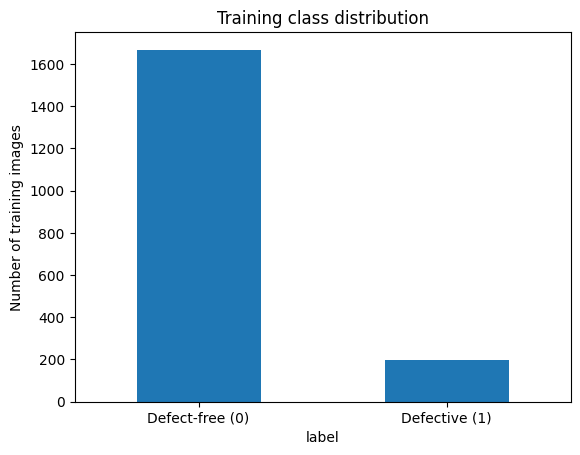

In [ ]:
for split_name, frame in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    labels = pd.to_numeric(frame[LABEL_COL], errors="coerce")
    if labels.isna().any() or not set(labels.unique()).issubset({0, 1}):
        raise ValueError(
            f"{split_name} labels must be numeric 0/1. Found: {frame[LABEL_COL].unique()}"
        )
    frame[LABEL_COL] = labels.astype(int)

print("Split sizes:")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Official test:", len(test_df))
print("Total:", len(train_df) + len(val_df) + len(test_df))

for name, frame in [("Training", train_df), ("Validation", val_df), ("Official test", test_df)]:
    counts = frame[LABEL_COL].value_counts().reindex([0, 1], fill_value=0)
    print(f"\n{name} class counts — 0=defect-free, 1=defective")
    display(counts.rename("image_count").to_frame())

train_df[LABEL_COL].value_counts().sort_index().plot(kind="bar", rot=0)
plt.xticks([0, 1], ["Defect-free (0)", "Defective (1)"])
plt.ylabel("Number of training images")
plt.title("Training class distribution")
plt.show()

## 8. Image preprocessing

Images are converted to RGB, resized to fit within 224×224 while preserving aspect ratio, and centered on a neutral canvas. No image is stretched or cropped. ImageNet mean and standard deviation are then applied.

Original size: (226, 637) | label: 0


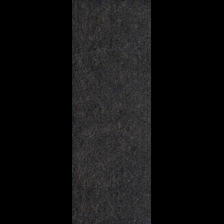

In [ ]:
IMAGE_SIZE = 224
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

class ResizeWithPadding:
    def __init__(self, size=224, fill=(0, 0, 0)):
        self.size = size
        self.fill = fill

    def __call__(self, image):
        image = image.convert("RGB")
        image.thumbnail((self.size, self.size), Image.Resampling.LANCZOS)
        canvas = Image.new("RGB", (self.size, self.size), self.fill)
        left = (self.size - image.width) // 2
        top = (self.size - image.height) // 2
        canvas.paste(image, (left, top))
        return canvas

image_transform = transforms.Compose([
    ResizeWithPadding(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

# Display one transformed training example.
sample_row = train_df.iloc[0]
with Image.open(sample_row["_resolved_image_path"]) as im:
    print("Original size:", im.size, "| label:", int(sample_row[LABEL_COL]))
    preview = ResizeWithPadding(IMAGE_SIZE)(im)
    display(preview)

## 9. Create PyTorch datasets and DataLoaders

The same deterministic preprocessing is used for all three splits. The official test loader is created for a later, explicitly optional evaluation only.

In [ ]:
class KolektorClassificationDataset(Dataset):
    def __init__(self, dataframe, image_column, label_column, transform):
        self.paths = dataframe["_resolved_image_path"].tolist()
        self.labels = dataframe[label_column].astype(int).tolist()
        self.transform = transform
        self.image_column = image_column

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        path = self.paths[index]
        try:
            with Image.open(path) as image:
                image = image.convert("RGB")
                tensor = self.transform(image)
        except Exception as exc:
            raise RuntimeError(f"Could not read image: {path}") from exc
        return tensor, int(self.labels[index])

BATCH_SIZE = 32
NUM_WORKERS = 2 if DEVICE.type == "cuda" else 0
pin_memory = DEVICE.type == "cuda"

train_dataset = KolektorClassificationDataset(train_df, IMAGE_COL, LABEL_COL, image_transform)
val_dataset = KolektorClassificationDataset(val_df, IMAGE_COL, LABEL_COL, image_transform)
test_dataset = KolektorClassificationDataset(test_df, IMAGE_COL, LABEL_COL, image_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=pin_memory)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=pin_memory)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=pin_memory)

print("Batches — train:", len(train_loader), "validation:", len(val_loader),
      "official test (reserved):", len(test_loader))

Batches — train: 59 validation: 15 official test (reserved): 32


## 10. Calculate class weights

Weights are calculated from **training labels only** and passed to `CrossEntropyLoss`. We do not use a weighted random sampler.

In [ ]:
train_counts = np.bincount(train_df[LABEL_COL].to_numpy(), minlength=2)
if np.any(train_counts == 0):
    raise ValueError(f"Both classes must occur in training data. Counts: {train_counts.tolist()}")

class_weights = len(train_df) / (2.0 * train_counts.astype(np.float32))
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32, device=DEVICE)

print("Training counts [class 0, class 1]:", train_counts.tolist())
print("Loss weights [class 0, class 1]:", class_weights.tolist())

Training counts [class 0, class 1]: [1667, 197]
Loss weights [class 0, class 1]: [0.5590881705284119, 4.730964660644531]


## 11. Build pretrained ResNet18

The ImageNet-pretrained ResNet18 final layer is replaced with a two-output layer. AdamW starts at learning rate `0.0001`.

In [ ]:
try:
    weights = models.ResNet18_Weights.DEFAULT
    model = models.resnet18(weights=weights)
except AttributeError:
    # Compatibility with older torchvision releases.
    model = models.resnet18(pretrained=True)

model.fc = nn.Linear(model.fc.in_features, 2)
model = model.to(DEVICE)

criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)

print(model.fc)
print("Model ready on:", DEVICE)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 134MB/s]


Linear(in_features=512, out_features=2, bias=True)
Model ready on: cuda


## 12. Train Model A with early stopping

Maximum 20 epochs; early stopping patience is 5. The best checkpoint is selected **only** by validation macro-F1. Training and validation loss/accuracy and validation macro-F1 are recorded each epoch.

In [ ]:
MAX_EPOCHS = 20
EARLY_STOPPING_PATIENCE = 5
CHECKPOINT_PATH = Path("/content/baseline_resnet18.pth")

history = {
    "train_loss": [], "val_loss": [],
    "train_accuracy": [], "val_accuracy": [],
    "val_macro_f1": []
}
best_val_f1 = -1.0
epochs_without_improvement = 0

def run_epoch(model, loader, optimizer=None):
    is_training = optimizer is not None
    model.train(is_training)
    running_loss = 0.0
    all_targets, all_predictions = [], []

    context = torch.enable_grad() if is_training else torch.no_grad()
    with context:
        for images, labels in tqdm(loader, leave=False):
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            if is_training:
                optimizer.zero_grad(set_to_none=True)

            logits = model(images)
            loss = criterion(logits, labels)

            if is_training:
                loss.backward()
                optimizer.step()

            running_loss += loss.item() * images.size(0)
            predictions = torch.argmax(logits, dim=1)
            all_targets.extend(labels.detach().cpu().numpy().tolist())
            all_predictions.extend(predictions.detach().cpu().numpy().tolist())

    average_loss = running_loss / len(loader.dataset)
    accuracy = accuracy_score(all_targets, all_predictions)
    macro_f1 = f1_score(all_targets, all_predictions, average="macro", zero_division=0)
    return average_loss, accuracy, macro_f1

for epoch in range(1, MAX_EPOCHS + 1):
    train_loss, train_acc, _ = run_epoch(model, train_loader, optimizer)
    val_loss, val_acc, val_macro_f1 = run_epoch(model, val_loader)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_acc)
    history["val_accuracy"].append(val_acc)
    history["val_macro_f1"].append(val_macro_f1)

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"train loss {train_loss:.4f} acc {train_acc:.4f} | "
        f"val loss {val_loss:.4f} acc {val_acc:.4f} "
        f"macro-F1 {val_macro_f1:.4f}"
    )

    if val_macro_f1 > best_val_f1:
        best_val_f1 = val_macro_f1
        epochs_without_improvement = 0
        checkpoint = {
            "model_state_dict": model.state_dict(),
            "architecture": "resnet18",
            "num_classes": 2,
            "class_names": ["Defect-free", "Defective"],
            "image_size": IMAGE_SIZE,
            "imagenet_mean": IMAGENET_MEAN,
            "imagenet_std": IMAGENET_STD,
            "best_validation_macro_f1": float(best_val_f1),
            "best_epoch": epoch,
            "class_weights": class_weights.tolist(),
            "optimizer": "AdamW",
            "learning_rate": 1e-4,
            "weight_decay": 1e-4,
            "seed": SEED
        }
        torch.save(checkpoint, CHECKPOINT_PATH)
        print(f"  Saved new best checkpoint → {CHECKPOINT_PATH}")
    else:
        epochs_without_improvement += 1
        print(f"  No validation macro-F1 improvement ({epochs_without_improvement}/{EARLY_STOPPING_PATIENCE})")

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print("Early stopping triggered.")
        break

print("\nTraining finished.")
print("Best validation macro-F1:", best_val_f1)
print("Best checkpoint:", CHECKPOINT_PATH)

  0%|          | 0/59 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

Epoch 01/20 | train loss 0.3934 acc 0.8428 | val loss 0.2739 acc 0.9379 macro-F1 0.8470
  Saved new best checkpoint → /content/baseline_resnet18.pth


  0%|          | 0/59 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a9cbfe8f1a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a9cbfe8f1a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

... (65 outputs left out)

Epoch 18/20 | train loss 0.0006 acc 1.0000 | val loss 0.3940 acc 0.9764 macro-F1 0.9317
  No validation macro-F1 improvement (4/5)


  0%|          | 0/59 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

Epoch 19/20 | train loss 0.0010 acc 1.0000 | val loss 0.3958 acc 0.9764 macro-F1 0.9317
  No validation macro-F1 improvement (5/5)
Early stopping triggered.

Training finished.
Best validation macro-F1: 0.9452113722576356
Best checkpoint: /content/baseline_resnet18.pth


## 13. Plot training curves

These plots show the actual values recorded during this run.

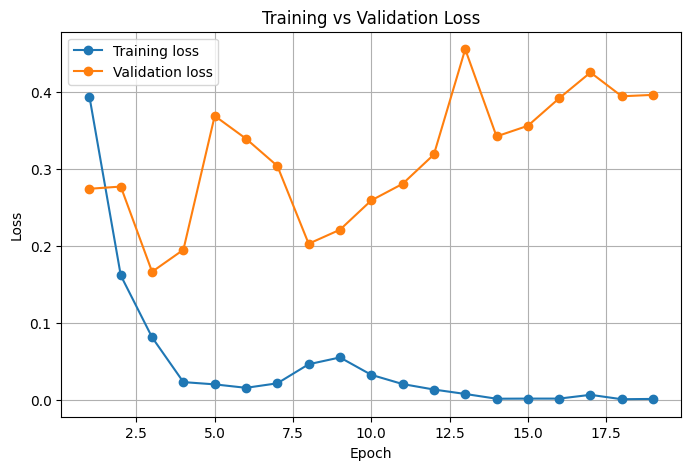

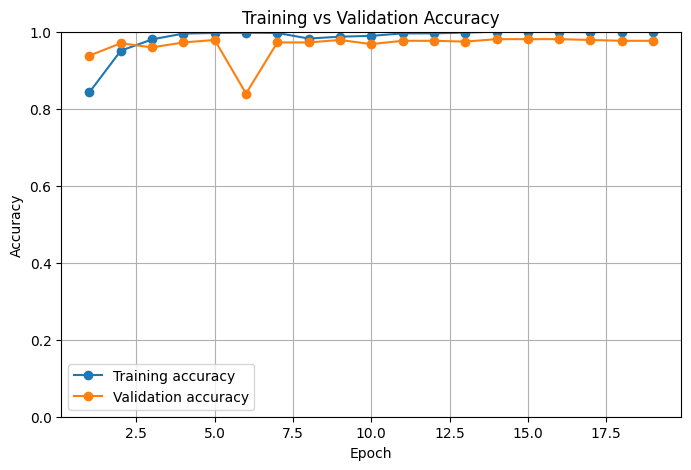

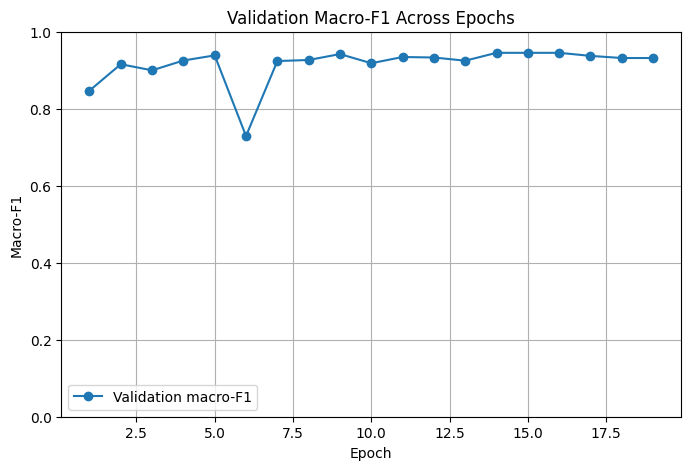

In [ ]:
epochs_ran = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs_ran, history["train_loss"], marker="o", label="Training loss")
plt.plot(epochs_ran, history["val_loss"], marker="o", label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("Training vs Validation Loss")
plt.grid(True); plt.legend(); plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epochs_ran, history["train_accuracy"], marker="o", label="Training accuracy")
plt.plot(epochs_ran, history["val_accuracy"], marker="o", label="Validation accuracy")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.title("Training vs Validation Accuracy")
plt.ylim(0, 1); plt.grid(True); plt.legend(); plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epochs_ran, history["val_macro_f1"], marker="o", label="Validation macro-F1")
plt.xlabel("Epoch"); plt.ylabel("Macro-F1"); plt.title("Validation Macro-F1 Across Epochs")
plt.ylim(0, 1); plt.grid(True); plt.legend(); plt.show()

## 14. Evaluate the best checkpoint on validation data

The checkpoint is reloaded before evaluation. This is the validation result for the best validation macro-F1 epoch.

  0%|          | 0/15 [00:00<?, ?it/s]

Best epoch: 14
Validation accuracy:  0.9807
Validation precision (macro): 0.9787
Validation recall (macro):    0.9172
Validation F1 (macro):         0.9452

Classification report:
              precision    recall  f1-score   support

 Defect-free       0.98      1.00      0.99       418
   Defective       0.98      0.84      0.90        49

    accuracy                           0.98       467
   macro avg       0.98      0.92      0.95       467
weighted avg       0.98      0.98      0.98       467



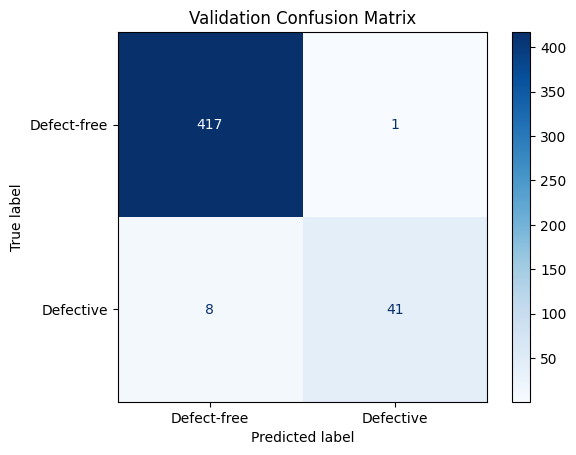

In [ ]:
checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE)
best_model = models.resnet18(weights=None)
best_model.fc = nn.Linear(best_model.fc.in_features, 2)
best_model.load_state_dict(checkpoint["model_state_dict"])
best_model = best_model.to(DEVICE)
best_model.eval()

def collect_predictions(model, loader):
    targets, predictions, probabilities = [], [], []
    model.eval()
    with torch.no_grad():
        for images, labels in tqdm(loader, leave=False):
            images = images.to(DEVICE, non_blocking=True)
            logits = model(images)
            probs = torch.softmax(logits, dim=1)
            preds = torch.argmax(probs, dim=1)
            targets.extend(labels.numpy().tolist())
            predictions.extend(preds.cpu().numpy().tolist())
            probabilities.extend(probs.cpu().numpy().tolist())
    return np.array(targets), np.array(predictions), np.array(probabilities)

val_targets, val_predictions, val_probabilities = collect_predictions(best_model, val_loader)

print(f"Best epoch: {checkpoint['best_epoch']}")
print(f"Validation accuracy:  {accuracy_score(val_targets, val_predictions):.4f}")
print(f"Validation precision (macro): {precision_score(val_targets, val_predictions, average='macro', zero_division=0):.4f}")
print(f"Validation recall (macro):    {recall_score(val_targets, val_predictions, average='macro', zero_division=0):.4f}")
print(f"Validation F1 (macro):         {f1_score(val_targets, val_predictions, average='macro', zero_division=0):.4f}")
print("\nClassification report:")
print(classification_report(
    val_targets, val_predictions,
    labels=[0, 1], target_names=["Defect-free", "Defective"], zero_division=0
))

cm = confusion_matrix(val_targets, val_predictions, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=["Defect-free", "Defective"]).plot(
    cmap="Blues", values_format="d"
)
plt.title("Validation Confusion Matrix")
plt.show()

## 15. Optional: final evaluation on the official test set

**Run this cell only when you are ready to record the baseline official-test results.**

The official test set has not been used for training, early stopping, hyperparameter selection, or checkpoint selection. After running this evaluation, avoid changing the baseline based on these test results if you want an unbiased comparison with later phases.

  0%|          | 0/32 [00:00<?, ?it/s]

OFFICIAL TEST RESULTS
Accuracy:  0.9661
Precision (macro): 0.9463
Recall (macro):    0.8734
F1 (macro):        0.9056

Classification report:
              precision    recall  f1-score   support

 Defect-free       0.97      0.99      0.98       894
   Defective       0.92      0.75      0.83       110

    accuracy                           0.97      1004
   macro avg       0.95      0.87      0.91      1004
weighted avg       0.97      0.97      0.96      1004



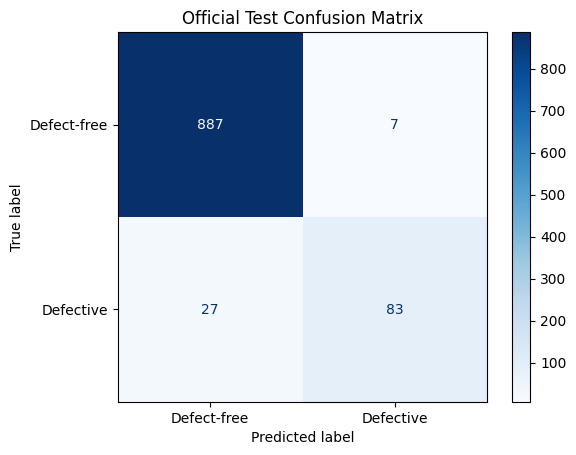

In [ ]:
# Optional final test evaluation — deliberately separate from training/model selection.
test_targets, test_predictions, test_probabilities = collect_predictions(best_model, test_loader)

print("OFFICIAL TEST RESULTS")
print(f"Accuracy:  {accuracy_score(test_targets, test_predictions):.4f}")
print(f"Precision (macro): {precision_score(test_targets, test_predictions, average='macro', zero_division=0):.4f}")
print(f"Recall (macro):    {recall_score(test_targets, test_predictions, average='macro', zero_division=0):.4f}")
print(f"F1 (macro):        {f1_score(test_targets, test_predictions, average='macro', zero_division=0):.4f}")
print("\nClassification report:")
print(classification_report(
    test_targets, test_predictions,
    labels=[0, 1], target_names=["Defect-free", "Defective"], zero_division=0
))
ConfusionMatrixDisplay(
    confusion_matrix(test_targets, test_predictions, labels=[0, 1]),
    display_labels=["Defect-free", "Defective"]
).plot(cmap="Blues", values_format="d")
plt.title("Official Test Confusion Matrix")
plt.show()

## 16. Single-image prediction

Upload one image. The trained best checkpoint and identical aspect-ratio-preserving preprocessing are used. The output includes both class probabilities.

Saving 20426.png to 20426 (1).png


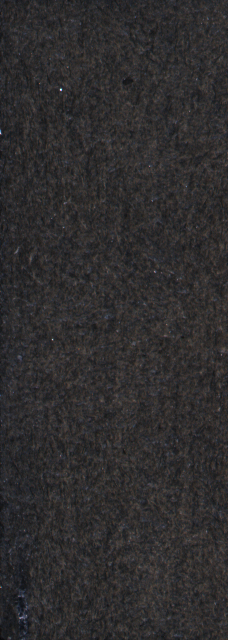


Prediction: Defect-free (class 0)
Probability — Defect-free (0): 99.7780%
Probability — Defective (1):   0.2220%


In [ ]:
from google.colab import files

single_upload = files.upload()
single_images = [
    name for name in single_upload
    if Path(name).suffix.lower() in {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
]
if not single_images:
    raise FileNotFoundError("Please upload one image file (PNG, JPG, JPEG, BMP, or TIFF).")

single_image_path = Path("/content") / single_images[0]
with Image.open(single_image_path) as image:
    display(image.convert("RGB"))
    input_tensor = image_transform(image.convert("RGB")).unsqueeze(0).to(DEVICE)

best_model.eval()
with torch.no_grad():
    logits = best_model(input_tensor)
    probabilities = torch.softmax(logits, dim=1)[0].cpu().numpy()

predicted_class = int(np.argmax(probabilities))
class_names = ["Defect-free", "Defective"]
print("\nPrediction:", class_names[predicted_class], f"(class {predicted_class})")
print(f"Probability — Defect-free (0): {probabilities[0]:.4%}")
print(f"Probability — Defective (1):   {probabilities[1]:.4%}")

## 17. Download the trained model

The checkpoint contains model weights, architecture and preprocessing metadata, best epoch, validation macro-F1, and training configuration.

In [ ]:
if not CHECKPOINT_PATH.exists():
    raise FileNotFoundError("Checkpoint not found. Complete training before downloading.")

print("Checkpoint size (MB):", round(CHECKPOINT_PATH.stat().st_size / (1024**2), 2))
from google.colab import files
files.download(str(CHECKPOINT_PATH))

In [ ]:
from google.colab import files
import os

checkpoint_file = "/content/baseline_resnet18.pth"
if os.path.exists(checkpoint_file):
    print(f"Downloading {checkpoint_file} ({round(os.path.getsize(checkpoint_file) / (1024**2), 2)} MB)...")
    files.download(checkpoint_file)
else:
    print("File not found. Please make sure the model training cell has completed and saved the checkpoint.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# 19. Phase 2 — Final Results and Observations

## 19.1 Project Objective

The objective of Phase 2 was to develop a baseline binary image classification model using only real KolektorSDD2 images.

An ImageNet-pretrained ResNet18 model was fine-tuned to classify industrial surface images into:

- Class 0: Defect-free
- Class 1: Defective

## 19.2 Model Configuration

| Parameter | Configuration |
|---|---|
| Architecture | ResNet18 |
| Pretrained weights | ImageNet |
| Input size | 224 × 224 |
| Number of classes | 2 |
| Optimizer | AdamW |
| Learning rate | 0.0001 |
| Loss function | Weighted CrossEntropyLoss |
| Maximum epochs | 20 |
| Early stopping patience | 5 |
| Best epoch | 14 |
| Model selection metric | Validation Macro-F1 |

## 19.3 Final Evaluation Results

### Validation Dataset

| Metric | Result |
|---|---:|
| Accuracy | 98.07% |
| Macro-F1 | 94.52% |
| Defective Precision | 97.62% |
| Defective Recall | 83.67% |
| Defective F1-score | 90.11% |
| False Negatives | 8 |

### Official Test Dataset

| Metric | Result |
|---|---:|
| Accuracy | 96.61% |
| Macro-F1 | 90.56% |
| Defective Precision | 92.22% |
| Defective Recall | 75.45% |
| Defective F1-score | 83.00% |
| False Negatives | 27 |

## 19.4 Limitations Observed

Although the baseline model achieved good overall accuracy, some defective images were incorrectly classified as defect-free.

The official test results showed:

- 27 defective images were incorrectly classified as defect-free.
- Defective-class recall was 75.45%.
- The model demonstrated difficulty identifying certain defective samples.

One observed example was image 20426.png.

Its ground-truth label was 1 (Defective), but the model predicted class 0 (Defect-free) with a defect-free probability of 99.778%.

This demonstrates that high prediction confidence does not necessarily guarantee a correct classification.

Small surface defects may be particularly challenging for image-level classification.

However, further experiments are required to establish the exact causes of these errors.

## 19.5 Conclusion

Phase 2 successfully established the first baseline classification model for DefectGen Studio.

The trained ResNet18 model provides a measurable reference point for future experiments.

The model achieved:

- 98.07% validation accuracy.
- 96.61% official test accuracy.
- 90.56% official test Macro-F1.

However, its defective-class recall indicates that there is room for improvement.

The trained checkpoint has been saved as:

`baseline_resnet18.pth`

## 19.6 Future Work

In the next phase, synthetic defective images will be investigated as an additional source of training data.

The objective will be to determine whether synthetic data can improve defective-image recognition compared with the original real-image baseline.

Model A will remain unchanged and will be preserved for comparison with future models.